<a href="https://colab.research.google.com/github/Lindaoctaviani7/Lindaoctaviani7-Machine-learning_Ganjil_TI3B_2026_244107020002/blob/main/Tugas1_JS9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


load data

In [ ]:
import numpy as np
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Data Saya/semester 5/pembelajaran mesin/voice.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8
df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


=== Peringkat Fitur Terbaik (Feature Importance) ===
1. meanfun: 0.3315
2. IQR: 0.2383
3. Q25: 0.1375
4. sd: 0.0757
5. sp.ent: 0.0368
6. sfm: 0.0241
7. centroid: 0.0195
8. mode: 0.0190
9. meanfreq: 0.0189
10. median: 0.0141
11. Q75: 0.0105
12. skew: 0.0099
13. maxdom: 0.0093
14. mindom: 0.0092
15. kurt: 0.0090
16. dfrange: 0.0089
17. minfun: 0.0087
18. meandom: 0.0077
19. modindx: 0.0069
20. maxfun: 0.0046

Fitur Top 5 terpilih: ['meanfun', 'IQR', 'Q25', 'sd', 'sp.ent']
Fitur Top 10 terpilih: ['meanfun', 'IQR', 'Q25', 'sd', 'sp.ent', 'sfm', 'centroid', 'mode', 'meanfreq', 'median']



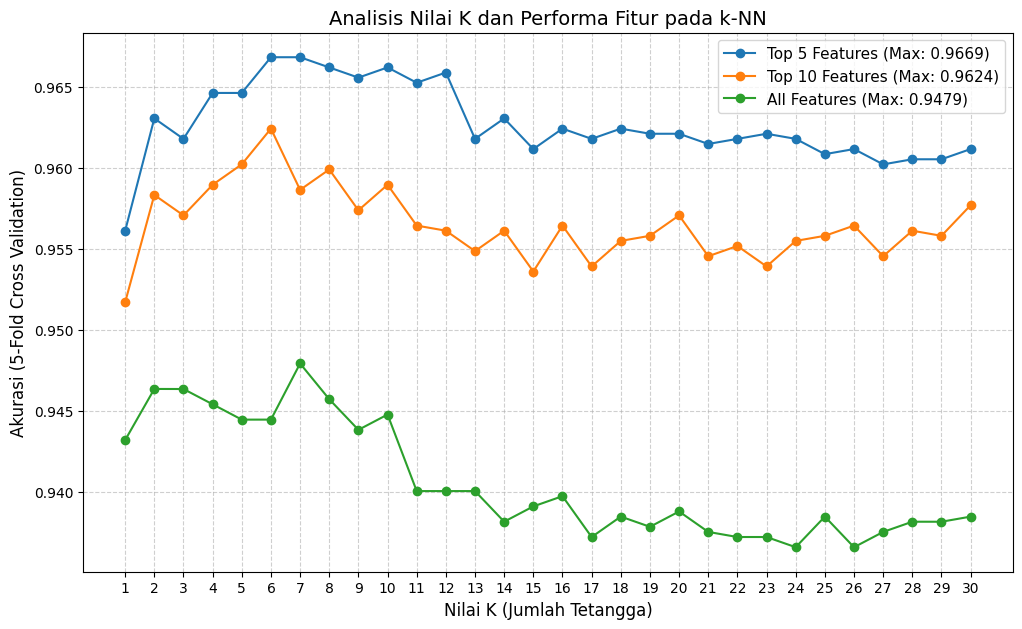

Top 5 Features -> Akurasi Terbaik: 0.9669 pada K = 6
Top 10 Features -> Akurasi Terbaik: 0.9624 pada K = 6
All Features -> Akurasi Terbaik: 0.9479 pada K = 7


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Persiapan Data
# Salin dataframe
data = df.copy()

# Encode target label (female: 0, male: 1)
data['label'] = data['label'].map({'female': 0, 'male': 1})

X = data.drop('label', axis=1)
y = data['label']

# Standardisasi seluruh fitur terlebih dahulu karena kNN sensitif terhadap skala
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# 2. Analisis Fitur Optimal (Menggunakan Random Forest Feature Importance)
rf = RandomForestClassifier(random_state=42)
rf.fit(X_scaled, y)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

print("=== Peringkat Fitur Terbaik (Feature Importance) ===")
for f in range(X.shape[1]):
    print(f"{f + 1}. {X.columns[indices[f]]}: {importances[indices[f]]:.4f}")

# Mengambil top-N fitur terbaik berdasarkan korelasi tinggi dan pentingnya fitur
# membandingkan performa model menggunakan 5, 10, dan seluruh fitur
top_5_features = list(X.columns[indices[:5]])
top_10_features = list(X.columns[indices[:10]])

print(f"\nFitur Top 5 terpilih: {top_5_features}")
print(f"Fitur Top 10 terpilih: {top_10_features}\n")

# 3. Eksperimen mencari Fitur Terbaik dan Nilai K Terbaik
k_range = range(1, 31)

results = {
    'Top 5 Features': [],
    'Top 10 Features': [],
    'All Features': []
}

feature_sets = {
    'Top 5 Features': top_5_features,
    'Top 10 Features': top_10_features,
    'All Features': list(X.columns)
}

for label, feat_list in feature_sets.items():
    X_subset = X_scaled[feat_list]
    for k in k_range:
        knn = KNeighborsClassifier(n_neighbors=k)
        # Menggunakan 5-Fold Cross Validation
        scores = cross_val_score(knn, X_subset, y, cv=5, scoring='accuracy')
        results[label].append(scores.mean())

# 4. Visualisasi Analisis Akurasi terhadap Nilai K
plt.figure(figsize=(12, 7))
for label, acc_scores in results.items():
    plt.plot(k_range, acc_scores, marker='o', label=f"{label} (Max: {max(acc_scores):.4f})")

plt.title('Analisis Nilai K dan Performa Fitur pada k-NN', fontsize=14)
plt.xlabel('Nilai K (Jumlah Tetangga)', fontsize=12)
plt.ylabel('Akurasi (5-Fold Cross Validation)', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

# Menampilkan kesimpulan parameter terbaik
for label, acc_scores in results.items():
    best_acc = max(acc_scores)
    best_k = k_range[acc_scores.index(best_acc)]
    print(f"{label} -> Akurasi Terbaik: {best_acc:.4f} pada K = {best_k}")